<a href="https://colab.research.google.com/github/gouthamsankar-clg/BIS_Lab/blob/main/Lab_3/AntColonyOptimisation_PCB_routing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Routing Optimization Complete ---
Optimal Wire Length Found: 24 grid steps.
Optimal Path Coordinates:
(1, 1) -> (1, 2) -> (1, 3) -> (2, 3) -> (3, 3) -> (3, 4) -> (3, 5) -> (3, 6) -> (4, 6) -> (4, 7) -> (4, 8) -> (4, 9) -> (4, 10) -> (5, 10) -> (6, 10) -> (7, 10) -> (7, 11) -> (8, 11) -> (9, 11) -> (9, 12) -> (9, 13) -> (10, 13) -> (11, 13) -> (12, 13) -> (13, 13)

Top Costlier Unique Routes Found:
- Length: 26 steps
- Length: 28 steps
- Length: 30 steps
- Length: 32 steps
- Length: 34 steps


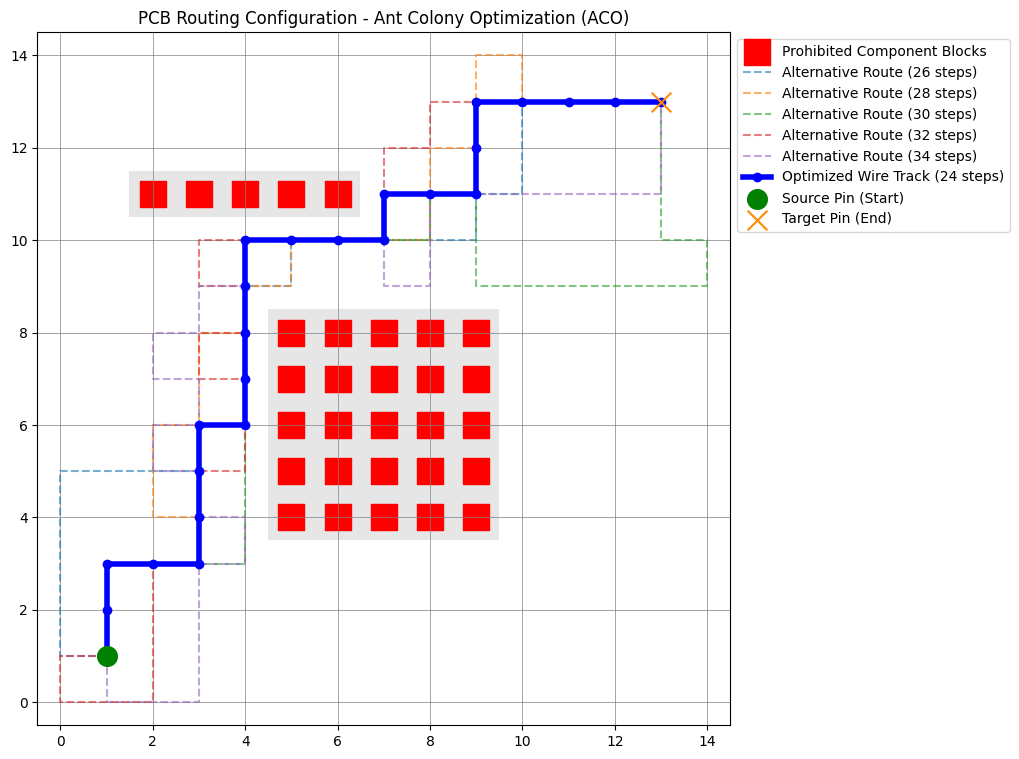

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

# =====================================================================
# 1. DEFINE THE PROBLEM ENVIRONMENT
# =====================================================================
GRID_WIDTH = 15
GRID_HEIGHT = 15

START_PIN = (1, 1)
END_PIN = (13, 13)

PROHIBITED_REGIONS = set()

for x in range(5, 10):
    for y in range(4, 9):
        PROHIBITED_REGIONS.add((x, y))

for x in range(2, 7):
    PROHIBITED_REGIONS.add((x, 11))

# =====================================================================
# 2. ALGORITHM CONFIGURATION & INITIALIZATION
# =====================================================================
NUM_AGENTS = 25
MAX_ITERATIONS = 50
ALPHA = 1.0
BETA = 3.0
RHO = 0.15

track_preference_matrix = np.ones((GRID_WIDTH, GRID_HEIGHT))

all_successful_tracks = {}

def manhattan_distance(cell, target):
    return abs(cell[0] - target[0]) + abs(cell[1] - target[1])

def get_valid_adjacent_moves(current, visited):
    cx, cy = current
    valid_moves = []
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for dx, dy in directions:
        nx, ny = cx + dx, cy + dy
        if 0 <= nx < GRID_WIDTH and 0 <= ny < GRID_HEIGHT:
            if (nx, ny) not in PROHIBITED_REGIONS and (nx, ny) not in visited:
                valid_moves.append((nx, ny))
    return valid_moves

# =====================================================================
# 3. MAIN CONSTRUCT & UPDATE LOOP
# =====================================================================
for iteration in range(MAX_ITERATIONS):
    current_iteration_tracks = []

    for agent in range(NUM_AGENTS):
        current_grid_cell = START_PIN
        wire_track = [START_PIN]
        visited_cells = {START_PIN}
        is_trapped = False

        while current_grid_cell != END_PIN:
            valid_moves = get_valid_adjacent_moves(current_grid_cell, visited_cells)

            if not valid_moves:
                is_trapped = True
                break

            cell_scores = []
            for cell in valid_moves:
                history_trace = track_preference_matrix[cell[0], cell[1]] ** ALPHA
                distance_heuristic = (1.0 / (manhattan_distance(cell, END_PIN) + 0.1)) ** BETA
                cell_scores.append(history_trace * distance_heuristic)

            total_score = sum(cell_scores)
            probabilities = [score / total_score for score in cell_scores]

            next_grid_cell = random.choices(valid_moves, weights=probabilities)[0]

            wire_track.append(next_grid_cell)
            visited_cells.add(next_grid_cell)
            current_grid_cell = next_grid_cell

        if not is_trapped:
            current_iteration_tracks.append(wire_track)
            track_tuple = tuple(wire_track)
            if track_tuple not in all_successful_tracks:
                all_successful_tracks[track_tuple] = len(wire_track) - 1

    # =====================================================================
    # 4. UPDATE TRACK PREFERENCES
    # =====================================================================
    track_preference_matrix *= (1 - RHO)

    for track in current_iteration_tracks:
        track_quality = 1.0 / len(track)
        for cell in track:
            track_preference_matrix[cell[0], cell[1]] += track_quality

# =====================================================================
# 5. VISUALIZATION ENGINE
# =====================================================================
sorted_tracks = sorted(all_successful_tracks.items(), key=lambda item: item[1])

global_best_track = list(sorted_tracks[0][0]) if sorted_tracks else []
min_wire_length = sorted_tracks[0][1] if sorted_tracks else 0

print(f"--- Routing Optimization Complete ---")
print(f"Optimal Wire Length Found: {min_wire_length} grid steps.")
print("Optimal Path Coordinates:")
print(" -> ".join([str(pos) for pos in global_best_track]))

print("\nTop Costlier Unique Routes Found:")
costlier_tracks = []
seen_lengths = {min_wire_length}
for track_tuple, length in sorted_tracks[1:]:
    if length not in seen_lengths and len(costlier_tracks) < 5:
        costlier_tracks.append((list(track_tuple), length))
        seen_lengths.add(length)
        print(f"- Length: {length} steps")

display_grid = np.zeros((GRID_WIDTH, GRID_HEIGHT))

for (ox, oy) in PROHIBITED_REGIONS:
    display_grid[ox, oy] = 1

plt.figure(figsize=(9, 9))
plt.imshow(display_grid.T, origin='lower', cmap='binary', alpha=0.1)
plt.grid(True, which='both', color='gray', linestyle='-', linewidth=0.5)

if PROHIBITED_REGIONS:
    obs_x = [p[0] for p in PROHIBITED_REGIONS]
    obs_y = [p[1] for p in PROHIBITED_REGIONS]
    plt.scatter(obs_x, obs_y, color='red', marker='s', s=350, label='Prohibited Component Blocks')

for i, (track, length) in enumerate(costlier_tracks):
    cx = [p[0] for p in track]
    cy = [p[1] for p in track]
    plt.plot(cx, cy, linestyle='--', linewidth=1.5, alpha=0.6, label=f'Alternative Route ({length} steps)')

if global_best_track:
    path_x = [p[0] for p in global_best_track]
    path_y = [p[1] for p in global_best_track]
    plt.plot(path_x, path_y, color='blue', linewidth=4, marker='o', markersize=6, label=f'Optimized Wire Track ({min_wire_length} steps)')

plt.scatter(START_PIN[0], START_PIN[1], color='green', marker='o', s=200, zorder=5, label='Source Pin (Start)')
plt.scatter(END_PIN[0], END_PIN[1], color='darkorange', marker='x', s=200, zorder=5, label='Target Pin (End)')

plt.title("PCB Routing Configuration - Ant Colony Optimization (ACO)", fontsize=12)
plt.xlim(-0.5, GRID_WIDTH - 0.5)
plt.ylim(-0.5, GRID_HEIGHT - 0.5)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()
